# VTK Time-Series Zone and Species Test

This notebook reads a full ASPECT/FastScape legacy VTK time series, extracts river habitat zones, evolves Magratheamorph fish species through time, and writes derived VTK copies that preserve the original FastScape fields while adding Magratheamorph fields.

The original VTK files are not modified.

In [183]:
import importlib
import sys
from pathlib import Path

repo_root = Path.cwd().resolve()
if (repo_root / "src").exists():
    sys.path.insert(0, str(repo_root / "src"))

import numpy as np
import matplotlib.pyplot as plt

from magratheamorph.readers import read_vtk_dem
import magratheamorph.lineage as lineage_module
import magratheamorph.visualization as visualization_module
import magratheamorph.zones as zones_module
import magratheamorph.model as model_module
import magratheamorph.outputs as outputs_module
import magratheamorph.vtk_output as vtk_output
importlib.reload(zones_module)
importlib.reload(model_module)
importlib.reload(outputs_module)
importlib.reload(vtk_output)
importlib.reload(lineage_module)
importlib.reload(visualization_module)
SpeciationModel = model_module.SpeciationModel
ZoneExtractor = zones_module.ZoneExtractor
remove_diagnostic_csvs = outputs_module.remove_diagnostic_csvs
write_zone_species_by_time_csv = outputs_module.write_zone_species_by_time_csv
plot_parent_daughter_tree = visualization_module.plot_parent_daughter_tree
plot_richness_map = visualization_module.plot_richness_map
plot_zone_map = visualization_module.plot_zone_map
from magratheamorph.vtk_output import magrathea_vtk_fields, write_legacy_vtk_with_point_fields, write_vtk_series_collection


In [192]:
INPUT_DIR = Path('/media/Samsung4TBSSD/research_data/tectonofish/output_fish_3d_t2/fastscape')
OUTPUT_DIR = Path('magrathea_vtk_time_series_output')
DERIVED_VTK_DIR = OUTPUT_DIR / 'vtk'

HABITAT_MODE = "drainage"
MIN_DRAINAGE_AREA = 1.0e7
MIN_ZONE_CELLS = 25
GAP_TOLERANCE_CELLS = 1
USE_CATCHMENTS = True
CONNECTIVITY = 8
MIN_ELEVATION = None
MAX_ELEVATION = None
TIME_TO_SPECIATION = 0
MIN_SPECIES_TRANSFER_CELLS = 1
TIME_SCALE = 1.0  # physical time per Topography file index; use 1.0 for raw indices
SEED_NEW_ZONES = True
SPECIES_PER_INITIAL_ZONE = 1
START_FRAME_INDEX = 10
SELECTED_FRAME_INDEX = -1
TARGET_SPECIES_ID = None  # set to an integer, e.g. 6, to write magrathea_species_6_presence

files = sorted(INPUT_DIR.glob('Topography*.vtk'))
print('input dir:', INPUT_DIR)
print('file count:', len(files))
print('first:', files[0].name if files else None)
print('last:', files[-1].name if files else None)
if not files:
    raise FileNotFoundError(f'No Topography*.vtk files found in {INPUT_DIR}')
if START_FRAME_INDEX < 0:
    START_FRAME_INDEX = len(files) + START_FRAME_INDEX
if START_FRAME_INDEX < 0 or START_FRAME_INDEX >= len(files):
    raise ValueError('START_FRAME_INDEX must select one of the input files')
print('Magratheamorph starts at index:', START_FRAME_INDEX, files[START_FRAME_INDEX].name)


input dir: /media/Samsung4TBSSD/research_data/tectonofish/output_fish_3d_t2/fastscape
file count: 51
first: Topography0000000.vtk
last: Topography0000250.vtk
Magratheamorph starts at index: 10 Topography0000050.vtk


In [193]:
def time_from_topography_name(path):
    return float(path.stem.replace('Topography', '')) * TIME_SCALE

sample_indices = sorted(set([0, len(files) // 2, len(files) - 1]))
for index in sample_indices:
    path = files[index]
    frame = read_vtk_dem(path, time=time_from_topography_name(path))
    print('\n', path.name)
    print('  metadata:', frame.metadata)
    print('  shape:', frame.shape)
    print('  elevation min/max:', float(np.nanmin(frame.elevation)), float(np.nanmax(frame.elevation)))
    print('  drainage p90/p95/p99/max:', [float(np.nanpercentile(frame.drainage_area, q)) for q in [90, 95, 99]], float(np.nanmax(frame.drainage_area)))
    print('  catchment count:', len(np.unique(frame.catchment)) if frame.catchment is not None else None)



 Topography0000000.vtk
  metadata: {'path': '/media/Samsung4TBSSD/research_data/tectonofish/output_fish_3d_t2/fastscape/Topography0000000.vtk', 'reader': 'legacy_vtk_structured_grid', 'elevation_field': 'topography', 'drainage_area_field': 'drainage_area', 'catchment_field': 'catchment'}
  shape: (227, 227)
  elevation min/max: -4.999998092651367 4.99954891204834
  drainage p90/p95/p99/max: [0.0, 0.0, 0.0] 0.0
  catchment count: 1

 Topography0000125.vtk
  metadata: {'path': '/media/Samsung4TBSSD/research_data/tectonofish/output_fish_3d_t2/fastscape/Topography0000125.vtk', 'reader': 'legacy_vtk_structured_grid', 'elevation_field': 'topography', 'drainage_area_field': 'drainage_area', 'catchment_field': 'catchment'}
  shape: (227, 227)
  elevation min/max: -574.4945068359375 609.5274658203125
  drainage p90/p95/p99/max: [6096873.500000001, 15810884.19999999, 248136979.20000026] 2012796032.0
  catchment count: 1

 Topography0000250.vtk
  metadata: {'path': '/media/Samsung4TBSSD/research

In [194]:
frames = []
for path in files:
    frames.append(read_vtk_dem(path, time=time_from_topography_name(path)))

def make_extractor():
    return ZoneExtractor(
        min_drainage_area=MIN_DRAINAGE_AREA,
        min_elevation=MIN_ELEVATION,
        max_elevation=MAX_ELEVATION,
        use_catchments=USE_CATCHMENTS,
        connectivity=CONNECTIVITY,
        min_zone_cells=MIN_ZONE_CELLS,
        gap_tolerance_cells=GAP_TOLERANCE_CELLS,
        habitat_mode=HABITAT_MODE,
    )

# Raw extraction is for diagnostics only. Biological zone IDs start at START_FRAME_INDEX.
raw_extractor = make_extractor()
raw_zone_maps = [raw_extractor.extract(frame, preserve_ids=False) for frame in frames]

model_extractor = make_extractor()
model = SpeciationModel(
    time_to_speciation=TIME_TO_SPECIATION,
    seed_new_zones=SEED_NEW_ZONES,
    min_species_transfer_cells=MIN_SPECIES_TRANSFER_CELLS,
)
model_zone_maps = [None] * len(frames)
previous = None
for index in range(START_FRAME_INDEX, len(frames)):
    zone_map = model_extractor.extract(frames[index], previous=previous)
    model_zone_maps[index] = zone_map
    if index == START_FRAME_INDEX:
        model.initialize(zone_map, species_per_zone=SPECIES_PER_INITIAL_ZONE)
    else:
        model.step(zone_map)
    previous = zone_map

active_zone_maps = [zone_map for zone_map in model_zone_maps if zone_map is not None]
times = [frame.time for frame in frames]
start_time = frames[START_FRAME_INDEX].time
raw_zone_counts = np.array([len(zone_map.zones) for zone_map in raw_zone_maps])
zone_counts = np.array([0 if zone_map is None else len(zone_map.zones) for zone_map in model_zone_maps])
species_counts_by_time = []
max_richness_by_time = []
for index, frame in enumerate(frames):
    zone_map = model_zone_maps[index]
    if zone_map is None:
        species_counts_by_time.append(0)
        max_richness_by_time.append(0)
        continue
    species_here = {row['species_id'] for row in model.range_table() if row['time'] == zone_map.time}
    species_counts_by_time.append(len(species_here))
    richness = model.richness_map_at(zone_map)
    max_richness_by_time.append(int(np.nanmax(richness)) if richness.size else 0)

print('frames:', len(frames))
print('raw zone count min/median/max:', int(raw_zone_counts.min()), float(np.median(raw_zone_counts)), int(raw_zone_counts.max()))
print('model zone count min/median/max:', int(zone_counts.min()), float(np.median(zone_counts)), int(zone_counts.max()))
print('pre-start frames:', START_FRAME_INDEX)
print('final species:', len([row for row in model.species_table() if row['extinction_time'] is None]))
print('total species ever:', len(model.species_table()))
print('events:', len(model.event_table()))


frames: 51
raw zone count min/median/max: 0 6.0 18
model zone count min/median/max: 0 5.0 11
pre-start frames: 10
final species: 35
total species ever: 60
events: 190


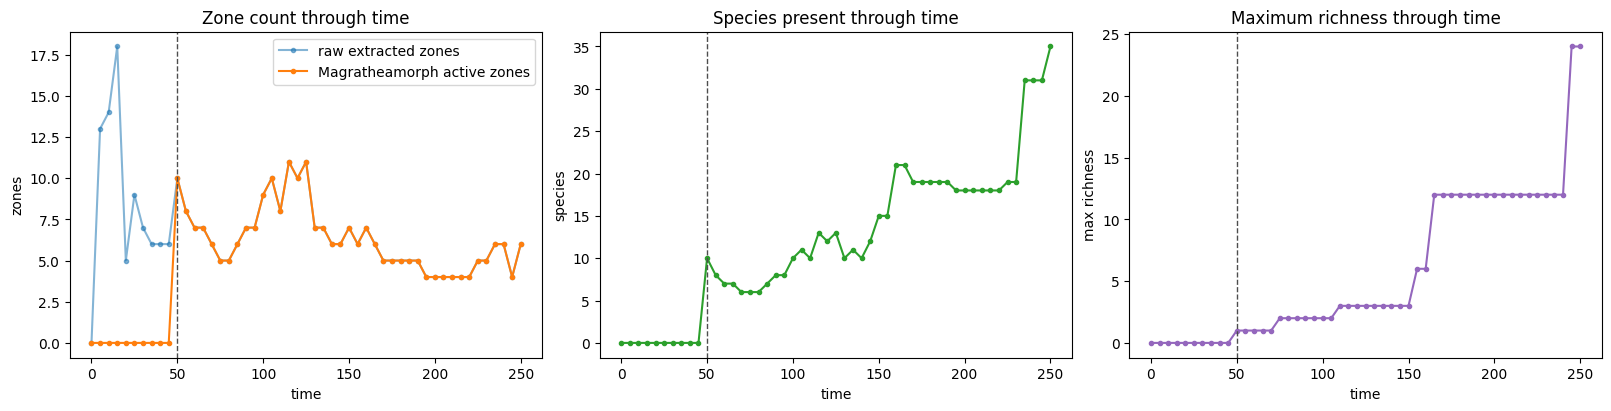

In [195]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(times, raw_zone_counts, marker='o', markersize=3, label='raw extracted zones', alpha=0.55)
axes[0].plot(times, zone_counts, marker='o', markersize=3, label='Magratheamorph active zones')
axes[0].axvline(start_time, color='0.3', linestyle='--', linewidth=1)
axes[0].set_title('Zone count through time')
axes[0].set_xlabel('time')
axes[0].set_ylabel('zones')
axes[0].legend()

axes[1].plot(times, species_counts_by_time, marker='o', markersize=3, color='tab:green')
axes[1].axvline(start_time, color='0.3', linestyle='--', linewidth=1)
axes[1].set_title('Species present through time')
axes[1].set_xlabel('time')
axes[1].set_ylabel('species')

axes[2].plot(times, max_richness_by_time, marker='o', markersize=3, color='tab:purple')
axes[2].axvline(start_time, color='0.3', linestyle='--', linewidth=1)
axes[2].set_title('Maximum richness through time')
axes[2].set_xlabel('time')
axes[2].set_ylabel('max richness')
plt.show()


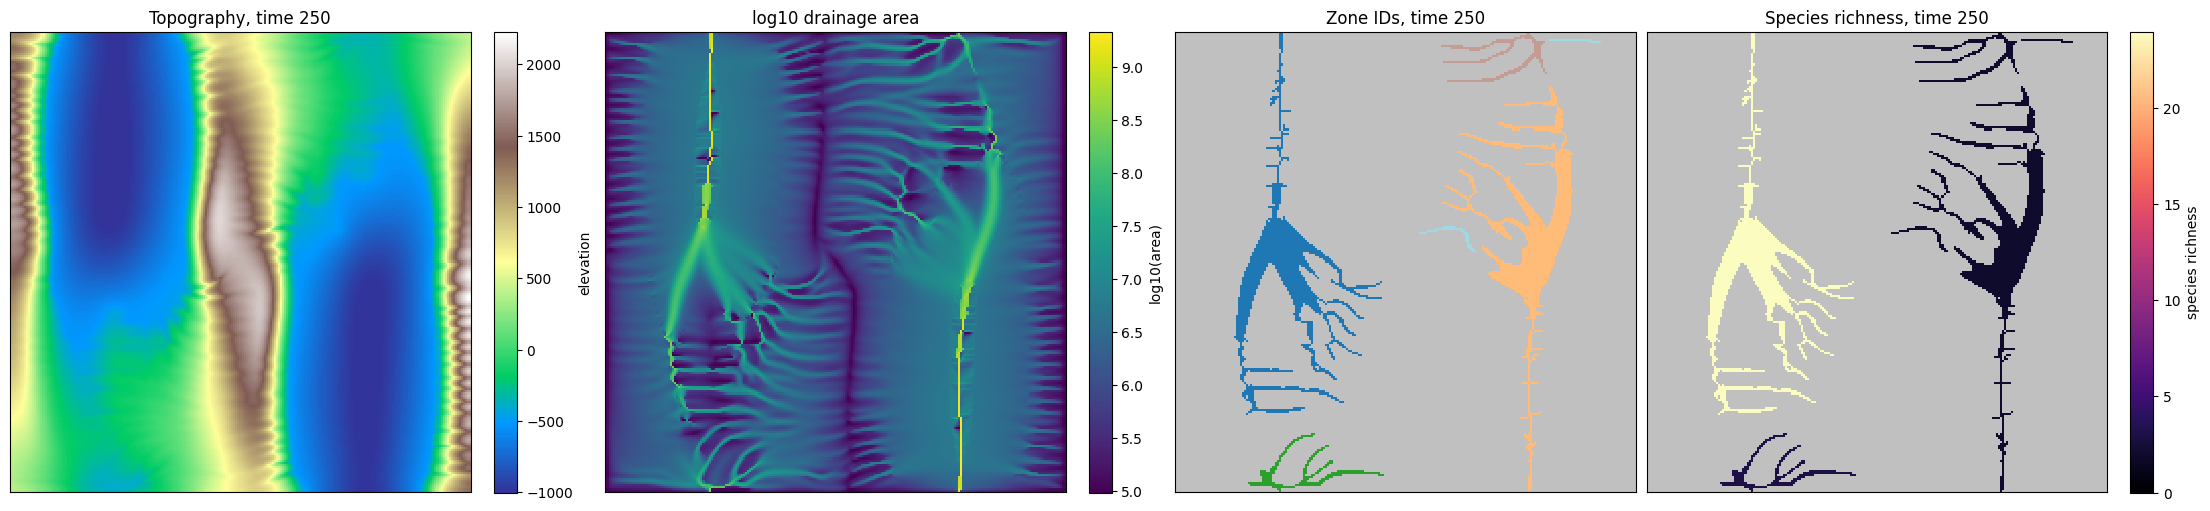

In [196]:
selected_index = SELECTED_FRAME_INDEX if SELECTED_FRAME_INDEX >= 0 else len(frames) + SELECTED_FRAME_INDEX
selected_frame = frames[selected_index]
selected_zone_map = model_zone_maps[selected_index]
positive_drainage = np.where(selected_frame.drainage_area > 0, selected_frame.drainage_area, np.nan)

fig, axes = plt.subplots(1, 4, figsize=(22, 5), constrained_layout=True)
im0 = axes[0].imshow(selected_frame.elevation, cmap='terrain', interpolation='nearest')
axes[0].set_title(f'Topography, time {selected_frame.time:g}')
axes[0].set_xticks([])
axes[0].set_yticks([])
fig.colorbar(im0, ax=axes[0], label='elevation')

im1 = axes[1].imshow(np.log10(positive_drainage), cmap='viridis', interpolation='nearest')
axes[1].set_title('log10 drainage area')
axes[1].set_xticks([])
axes[1].set_yticks([])
fig.colorbar(im1, ax=axes[1], label='log10(area)')

if selected_zone_map is None:
    zero = np.zeros(selected_frame.shape, dtype=int)
    im2 = axes[2].imshow(zero, cmap='Greys', interpolation='nearest', vmin=0, vmax=1)
    axes[2].set_title(f'Magratheamorph zones inactive, time {selected_frame.time:g}')
    axes[2].set_xticks([])
    axes[2].set_yticks([])
    im3 = axes[3].imshow(zero, cmap='magma', interpolation='nearest', vmin=0)
    axes[3].set_title(f'Species richness inactive, time {selected_frame.time:g}')
    axes[3].set_xticks([])
    axes[3].set_yticks([])
else:
    plot_zone_map(axes[2], selected_zone_map, show_labels=False)
    im3 = plot_richness_map(axes[3], model, selected_zone_map, show_labels=False)
fig.colorbar(im3, ax=axes[3], label='species richness')
plt.show()


In [197]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DERIVED_VTK_DIR.mkdir(parents=True, exist_ok=True)

remove_diagnostic_csvs(OUTPUT_DIR)
write_zone_species_by_time_csv(OUTPUT_DIR / 'zone_species_by_time.csv', model, active_zone_maps)

derived_vtk_paths = []
for index, input_path in enumerate(files):
    zone_map = model_zone_maps[index]
    output_path = DERIVED_VTK_DIR / f'{input_path.stem}_magrathea.vtk'
    target_field_name = None if TARGET_SPECIES_ID is None else f'magrathea_species_{int(TARGET_SPECIES_ID)}_presence'
    if zone_map is None:
        zero = np.zeros(frames[index].shape, dtype=np.int32)
        fields = {
            'magrathea_zone_id': zero,
            'magrathea_species_richness': zero,
        }
        if target_field_name is not None:
            fields[target_field_name] = zero
    else:
        richness = model.richness_map_at(zone_map)
        fields = magrathea_vtk_fields(zone_map, richness)
        if target_field_name is not None:
            fields[target_field_name] = model.species_presence_map_at(zone_map, int(TARGET_SPECIES_ID)).astype(np.int32)
    write_legacy_vtk_with_point_fields(input_path, output_path, fields)
    derived_vtk_paths.append(output_path)

series_path = OUTPUT_DIR / 'magrathea_timeseries.vtk.series'
write_vtk_series_collection(series_path, derived_vtk_paths, timesteps=times)

print('wrote zone-species CSV:', (OUTPUT_DIR / 'zone_species_by_time.csv').resolve())
print('derived VTK files:', len(derived_vtk_paths))
print('ParaView time-series file:', series_path.resolve())


wrote zone-species CSV: /home/ad3.ucdavis.edu/tylxue/Documents/research/code/MagratheaMorph/notebooks/magrathea_vtk_time_series_output/zone_species_by_time.csv
derived VTK files: 51
ParaView time-series file: /home/ad3.ucdavis.edu/tylxue/Documents/research/code/MagratheaMorph/notebooks/magrathea_vtk_time_series_output/magrathea_timeseries.vtk.series


In [190]:
# Read back derived VTK files to confirm pre-start fields are zero and active fields are nonzero.
from magratheamorph.vtk_output import read_legacy_vtk_point_fields

prestart_path = DERIVED_VTK_DIR / f'{files[0].stem}_magrathea.vtk'
prestart_fields = read_legacy_vtk_point_fields(prestart_path)
print(prestart_path)
print('pre-start zone min/max:', int(np.nanmin(prestart_fields['magrathea_zone_id'])), int(np.nanmax(prestart_fields['magrathea_zone_id'])))
print('pre-start richness min/max:', int(np.nanmin(prestart_fields['magrathea_species_richness'])), int(np.nanmax(prestart_fields['magrathea_species_richness'])))

check_index = selected_index if model_zone_maps[selected_index] is not None else START_FRAME_INDEX
check_path = DERIVED_VTK_DIR / f'{files[check_index].stem}_magrathea.vtk'
fields = read_legacy_vtk_point_fields(check_path)
print('\n', check_path)
print('field count:', len(fields))
print('fields:', sorted(fields))
print('active zone min/max:', int(np.nanmin(fields['magrathea_zone_id'])), int(np.nanmax(fields['magrathea_zone_id'])))
print('active richness min/max:', int(np.nanmin(fields['magrathea_species_richness'])), int(np.nanmax(fields['magrathea_species_richness'])))
if TARGET_SPECIES_ID is not None:
    target_field_name = f'magrathea_species_{int(TARGET_SPECIES_ID)}_presence'
    print('target species field:', target_field_name)
    print('target species presence min/max:', int(np.nanmin(fields[target_field_name])), int(np.nanmax(fields[target_field_name])))


magrathea_vtk_time_series_output/vtk/Topography0000000_magrathea.vtk
pre-start zone min/max: 0 0
pre-start richness min/max: 0 0

 magrathea_vtk_time_series_output/vtk/Topography0000250_magrathea.vtk
field count: 9
fields: ['HHHHH', 'basement', 'catchment', 'drainage_area', 'erosion_rate', 'magrathea_species_richness', 'magrathea_zone_id', 'topography', 'total_erosion']
active zone min/max: -1 38
active richness min/max: 0 24


## Parent-daughter species tree


In [ ]:
plt.close("all")
import magratheamorph.lineage as lineage_module
import magratheamorph.visualization as visualization_module
importlib.reload(lineage_module)
importlib.reload(visualization_module)
plot_parent_daughter_tree = visualization_module.plot_parent_daughter_tree

species_rows = model.species_table()
parent_daughter = [row for row in species_rows if row["parent_id"] is not None]
height = 4.8
fig, ax = plt.subplots(figsize=(10, height), constrained_layout=True)
plot_parent_daughter_tree(
    ax,
    species_rows,
    end_time=max(zone_map.time for zone_map in active_zone_maps),
    label_mode="all",
    max_labeled_species=10000,
    style="rectangular",
    time_unit="year",
    label_position="end",
    label_fontsize=6.5,
    time_block_cmap="Greens",
    time_block_count=5,
    show_time_blocks=True,
    compact_extinct=True,
    show_extinct_labels=True,
    extinct_label_suffix="",
    split_color="tab:red",
    split_marker=True,
    split_marker_color="tab:red",
    split_marker_size=4.2,
    split_linewidth=1.4,
)
plt.show()
